<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_7/tugas_praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS PRAKTIKUM**
### **Instruksi Umum:**

Anda akan menggunakan dataset "Medical Cost Personal Datasets". Pastikan Anda telah mengunduh dataset ini.

Gunakan bahasa pemrograman Python dan library yang sesuai seperti NumPy, Pandas, Matplotlib dan Scikit-Learn untuk melakukan analisis regresi dan SVR.

### **Tugas 1: Multiple Linear Regression**

1. Identifikasi variabel-variabel yang akan digunakan sebagai variabel bebas (fitur) dan variabel target (biaya medis personal).

2. Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

3. Lakukan feature scaling jika diperlukan.

4. Buat model multiple linear regression menggunakan Scikit-Learn.

5. Latih model pada data latih dan lakukan prediksi pada data uji.

6. Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.

### **Catatan Tambahan:**

1. Pastikan untuk memberikan penjelasan singkat tentang dataset yang digunakan, termasuk deskripsi variabel-variabel yang relevan.

2. Tampilkan visualisasi data yang relevan seperti scatter plot atau grafik lainnya jika diperlukan untuk pemahaman yang lebih baik.

3. Analisis hasil yang Anda dapatkan dalam tugas praktikum Anda.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [4]:
df = pd.read_csv('insurance.csv')

df_encoded = pd.get_dummies(df, drop_first=True)

# Identifikasi Variabel Bebas (X) dan Target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

In [5]:
# Pembagian Dataset (Train dan Test dengan proporsi 80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# Membuat Model Multiple Linear Regression
model = LinearRegression()

In [8]:
# Melatih Model dan Melakukan Prediksi
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

In [9]:
# Evaluasi Model
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"R-squared: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

R-squared: 0.7836
MSE: 33596915.8514
RMSE: 5796.2847
MAE: 4181.1945


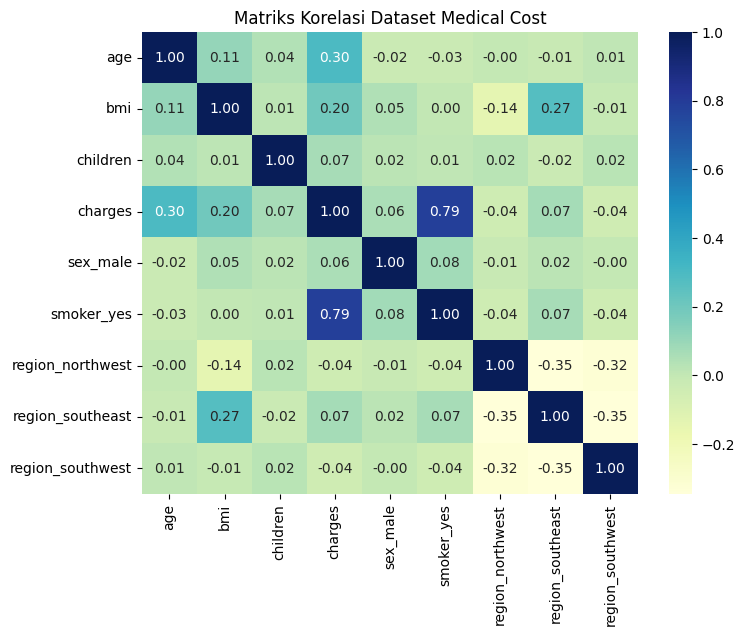

In [10]:
# Visualisasi Korelasi Antarvariabel
plt.figure(figsize=(8, 6))
sns.heatmap(df_encoded.corr(), annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Matriks Korelasi Dataset Medical Cost')
plt.show()

### **Catatan Tambahan**

1. Berikut adalah deskripsi variabel yang relevan dalam dataset yang digunakan:
  - `age`: Usia penerima manfaat dalam tahun.
  - `sex`: Jenis kelamin penerima manfaat (pria atau wanita).
  - `bmi`: Indeks massa tubuh yang menunjukkan proporsi berat badan terhadap tinggi badan.
  - `children`: Jumlah anak atau tanggungan yang tercakup dalam asuransi kesehatan.
  - `smoker`: Status merokok seseorang (ya atau tidak).
  - `region`: Wilayah tempat tinggal di Amerika Serikat (terbagi menjadi northeast, southeast, southwest, dan northwest).
  - `charges`: Biaya medis personal yang ditagihkan oleh asuransi kesehatan sebagai variabel target.
2. Tampilan visualisasi data yang relevan seperti scatter plot atau grafik lainnya untuk pemahaman yang lebih baik.

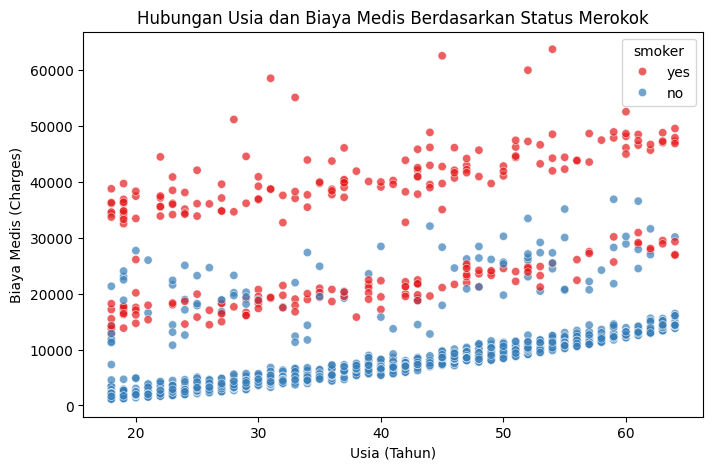

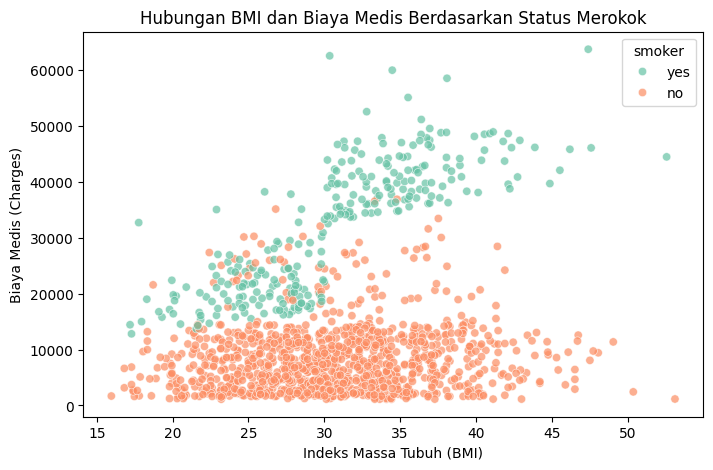

In [11]:
df = pd.read_csv('insurance.csv')

# Scatter Plot 1: Hubungan Usia dan Biaya Medis Berdasarkan Status Merokok
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette='Set1', alpha=0.7)
plt.title('Hubungan Usia dan Biaya Medis Berdasarkan Status Merokok')
plt.xlabel('Usia (Tahun)')
plt.ylabel('Biaya Medis (Charges)')
plt.show()

# Scatter Plot 2: Hubungan BMI dan Biaya Medis Berdasarkan Status Merokok
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette='Set2', alpha=0.7)
plt.title('Hubungan BMI dan Biaya Medis Berdasarkan Status Merokok')
plt.xlabel('Indeks Massa Tubuh (BMI)')
plt.ylabel('Biaya Medis (Charges)')
plt.show()

3. Analisis hasil praktik regresi linier berganda pada dataset asuransi:
  - Evaluasi Kinerja ModelSkor
      - R^2 Sebesar 0,7836<br>
      Model regresi linier mampu menjelaskan sekitar 78,36% keragaman biaya medis dalam dataset, yang menunjukkan tingkat kesesuaian model yang cukup baik.
      - Nilai Error (MSE, RMSE, dan MAE)<br>
      Nilai RMSE sebesar 5.796,28 dan MAE sebesar 4.181,19 mencerminkan rata-rata besar deviasi prediksi biaya dari nilai aslinya, yang dipengaruhi oleh sebaran data biaya medis dengan rentang yang luas.
  - Pola Hubungan Variabel
      - Pengaruh Status Merokok<br>
      Berdasarkan visualisasi, status perokok menjadi faktor pembeda utama yang menaikkan biaya medis secara signifikan dibanding bukan perokok.
      - Pengaruh Usia dan BMI<br>
      Biaya medis cenderung meningkat linier seiring bertambahnya usia, sementara kombinasi BMI tinggi dan status perokok aktif membentuk kelompok biaya tertinggi pada dataset.